<a href="https://colab.research.google.com/github/hanifsyahrulramadhan424-blip/preprocessing-data-automobile/blob/main/HanifSyahrulRamadhan_TugasPreprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Tahap 1: Persiapan dan Pembacaan Data

Langkah pertama adalah menyiapkan lingkungan Python kita dengan mengimpor pustaka (library) yang dibutuhkan, mengunggah file data, dan membacanya ke dalam bentuk tabel (DataFrame).

In [ ]:
# Impor pustaka yang diperlukan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Meminta pengguna untuk mengunggah file
print("Silakan unggah file 'Data Automobile.xlsx'")
uploaded = files.upload()

# Dapatkan nama file yang diunggah
file_name = list(uploaded.keys())[0]

# Baca Sheet1 menggunakan pandas
# Karena file sudah memiliki header, kita langsung membacanya
df_awal = pd.read_excel(file_name, sheet_name='Sheet1')

# Simpan salinan data asli agar tidak berubah saat kita melakukan preprocessing
df = df_awal.copy()

print("\nData berhasil diunggah dan dibaca!")

Silakan unggah file 'Data Automobile.xlsx'


Saving Data Automobile.xlsx to Data Automobile (1).xlsx

Data berhasil diunggah dan dibaca!


## Tahap 2: Pemeriksaan Awal

Sekarang kita akan melihat struktur dan isi awal dari data yang baru saja kita baca. Ini penting untuk mengenali tipe kolom dan potensi masalah.

In [ ]:
# Tampilkan lima baris pertama
print("\n--- Lima Baris Pertama Data ---")
display(df.head())

# Tampilkan jumlah baris dan kolom
print(f"\nJumlah Baris: {df.shape[0]}")
print(f"Jumlah Kolom: {df.shape[1]}")

# Tampilkan informasi tipe data tiap kolom
print("\n--- Informasi Data ---")
df.info()

# Tampilkan statistik deskriptif awal
print("\n--- Statistik Deskriptif ---")
display(df.describe(include='all'))

# Hitung nilai kosong, tanda '?', dan baris duplikat di data mentah
print("\n--- Pemeriksaan Masalah Awal ---")
print("Jumlah baris duplikat:", df.duplicated().sum())
print("Jumlah nilai kosong bawaan (NaN):", df.isna().sum().sum())
# Mencari tanda '?' karena sering dipakai sebagai tanda nilai yang hilang di dataset ini
print("Jumlah tanda '?':", (df == '?').sum().sum())


--- Lima Baris Pertama Data ---


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450



Jumlah Baris: 205
Jumlah Kolom: 26

--- Informasi Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       205 non-null    object 
 6   body-style         205 non-null    object 
 7   drive-wheels       205 non-null    object 
 8   engine-location    205 non-null    object 
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    object 
 15  num-of-cylinde

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
count,205.000000,205,205,205,205,205,205,205,205,205.000000,...,205.000000,205,205.00,205.0,205.000000,205.0,205.0,205.000000,205.000000,205
unique,NaN,52,22,2,2,3,5,3,2,NaN,...,NaN,8,39.00,37.0,NaN,60.0,24.0,NaN,NaN,187
top,NaN,?,toyota,gas,std,four,sedan,fwd,front,NaN,...,NaN,mpfi,3.62,3.4,NaN,68.0,5500.0,NaN,NaN,?
freq,NaN,41,32,185,168,114,96,120,202,NaN,...,NaN,94,23.00,20.0,NaN,19.0,37.0,NaN,NaN,4
mean,0.834146,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.756585,...,126.907317,NaN,NaN,NaN,10.142537,NaN,NaN,25.219512,30.751220,NaN
std,1.245307,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.021776,...,41.642693,NaN,NaN,NaN,3.972040,NaN,NaN,6.542142,6.886443,NaN
min,-2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86.600000,...,61.000000,NaN,NaN,NaN,7.000000,NaN,NaN,13.000000,16.000000,NaN
25%,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,94.500000,...,97.000000,NaN,NaN,NaN,8.600000,NaN,NaN,19.000000,25.000000,NaN
50%,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,97.000000,...,120.000000,NaN,NaN,NaN,9.000000,NaN,NaN,24.000000,30.000000,NaN
75%,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,102.400000,...,141.000000,NaN,NaN,NaN,9.400000,NaN,NaN,30.000000,34.000000,NaN



--- Pemeriksaan Masalah Awal ---
Jumlah baris duplikat: 0
Jumlah nilai kosong bawaan (NaN): 0
Jumlah tanda '?': 59


## Tahap 3: Pembersihan dan Perbaikan Tipe Data

Pada tahap ini, kita akan membersihkan spasi berlebih, mengubah karakter seperti '?' menjadi nilai kosong (NaN) yang dikenali sistem, dan memastikan tipe data sesuai (angka atau teks). Kita juga akan mengubah kata-kata penyebut jumlah (seperti 'two', 'four') menjadi angka numerik sesungguhnya.

In [ ]:
# Fungsi bantuan untuk menghapus spasi berlebih di awal/akhir teks
def hapus_spasi(teks):
    if isinstance(teks, str):
        return teks.strip()
    return teks

# Terapkan fungsi hapus_spasi ke seluruh sel dalam DataFrame
df = df.applymap(hapus_spasi)

# Ubah tanda '?' dan teks kosong ('') menjadi NaN
df = df.replace('?', np.nan)
df = df.replace('', np.nan)

# Pemetaan untuk kolom jumlah pintu dan silinder dari kata ke angka
num_mapping = {
    'two': 2, 'three': 3, 'four': 4, 'five': 5,
    'six': 6, 'eight': 8, 'twelve': 12
}

# Proses konversi teks ke angka pada kolom 'num-of-doors' dan 'num-of-cylinders'
for col in ['num-of-doors', 'num-of-cylinders']:
    if col in df.columns:
        # Cek apakah ada nilai yang tidak dikenali dalam pemetaan
        unique_vals = df[col].dropna().unique()
        for val in unique_vals:
            if isinstance(val, str) and val not in num_mapping:
                print(f"Peringatan: Nilai '{val}' di kolom {col} tidak dikenali.")
        # Ganti dengan angka menggunakan map (nilai yang tak ada di map jadi NaN)
        df[col] = df[col].map(num_mapping).fillna(df[col]) # fillna utk pertahankan nilai yg sdh angka

# Daftar kolom yang seharusnya numerik
kolom_numerik = [
    'normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight',
    'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower',
    'peak-rpm', 'city-mpg', 'highway-mpg', 'price', 'num-of-doors', 'num-of-cylinders'
]

# Konversi ke tipe numerik
for col in kolom_numerik:
    if col in df.columns:
        # Cek nilai yang tak bisa diubah jadi angka (non-numeric)
        invalid_vals = pd.to_numeric(df[col], errors='coerce').isna() & df[col].notna()
        if invalid_vals.any():
            print(f"Peringatan: Nilai tidak valid ditemukan di kolom '{col}' sebelum konversi. Nilai ini akan menjadi NaN.")
        # Konversi paksa (errors='coerce' membuat error menjadi NaN)
        df[col] = pd.to_numeric(df[col], errors='coerce')

print("\nPembersihan dan konversi tipe data selesai.")


Pembersihan dan konversi tipe data selesai.


/tmp/ipykernel_2235/629201226.py:8: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df.applymap(hapus_spasi)
/tmp/ipykernel_2235/629201226.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace('?', np.nan)
/tmp/ipykernel_2235/629201226.py:29: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].map(num_mapping).fillna(df[col]) # fillna utk pertahankan nilai yg sdh angka


## Tahap 4: Penanganan Missing Values (Nilai Hilang)

Data sering kali tidak lengkap. Kita akan mengisi nilai-nilai kosong tersebut dengan metode yang wajar, seperti median untuk angka, dan modus (nilai paling sering muncul) untuk kategori diskrit atau teks. Kita juga akan merekam pengisian ini sebagai rekam jejak (audit).

In [ ]:
# Tampilkan persentase missing values setelah tanda '?' dibersihkan
print("\n--- Persentase Missing Values ---")
missing_info = df.isna().sum()
missing_percent = (missing_info / len(df)) * 100
missing_df = pd.DataFrame({'Jumlah Kosong': missing_info, 'Persentase (%)': missing_percent})
display(missing_df[missing_df['Jumlah Kosong'] > 0])

# Tabel rekam jejak imputasi
audit_imputasi = []

# Proses pengisian nilai kosong
for col in df.columns:
    if df[col].isna().sum() > 0:
        jumlah_kosong = df[col].isna().sum()

        # Jika kolom adalah diskrit/ordinal atau teks, gunakan modus
        if col in ['num-of-doors', 'num-of-cylinders'] or df[col].dtype == 'object':
            nilai_pengganti = df[col].mode()[0]
            metode = 'Modus'
        # Jika numerik kontinu, gunakan median
        else:
            nilai_pengganti = df[col].median()
            metode = 'Median'
            if col == 'price':
                print(f"Catatan: Nilai 'price' yang kosong diisi dengan {nilai_pengganti} (Median). Ini adalah hasil imputasi, bukan harga asli.")

        # Terapkan pengisian nilai
        df[col].fillna(nilai_pengganti, inplace=True)

        # Catat dalam tabel audit
        audit_imputasi.append({
            'Kolom': col,
            'Jumlah Diisi': jumlah_kosong,
            'Metode': metode,
            'Nilai Pengganti': nilai_pengganti
        })

# Buat DataFrame untuk tabel audit
df_audit = pd.DataFrame(audit_imputasi)

print("\n--- Ringkasan Imputasi ---")
if not df_audit.empty:
    display(df_audit)
else:
    print("Tidak ada missing values yang perlu diimputasi.")


--- Persentase Missing Values ---


,Jumlah Kosong,Persentase (%)
normalized-losses,41,20.00000
num-of-doors,2,0.97561
bore,4,1.95122
stroke,4,1.95122
horsepower,2,0.97561
peak-rpm,2,0.97561
price,4,1.95122


Catatan: Nilai 'price' yang kosong diisi dengan 10295.0 (Median). Ini adalah hasil imputasi, bukan harga asli.

--- Ringkasan Imputasi ---


/tmp/ipykernel_2235/1301188784.py:28: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(nilai_pengganti, inplace=True)


,Kolom,Jumlah Diisi,Metode,Nilai Pengganti
0,normalized-losses,41,Median,115.00
1,num-of-doors,2,Modus,4.00
2,bore,4,Median,3.31
3,stroke,4,Median,3.29
4,horsepower,2,Median,95.00
5,peak-rpm,2,Median,5200.00
6,price,4,Median,10295.00


## Tahap 5: Pemeriksaan Duplikasi dan Outlier

Selanjutnya kita melihat apakah ada baris data yang identik secara keseluruhan (duplikat). Kita juga memeriksa keberadaan outlier (pencilan) pada kolom numerik menggunakan metode statistik IQR (Interquartile Range) dan visualisasi Boxplot. Ingat, kita hanya mendeteksi, bukan menghapusnya, karena mobil bisa saja memiliki fitur ekstrem yang valid (seperti harga atau ukuran mesin yang sangat tinggi).


--- Duplikasi Data ---
Jumlah baris duplikat yang ditemukan: 0

--- Deteksi Outlier (Metode IQR) ---


,Kolom,Jumlah Outlier
0,price,14
1,horsepower,6
2,engine-size,10
3,normalized-losses,8
4,wheel-base,3
5,length,1
6,width,8
8,city-mpg,2
9,highway-mpg,3


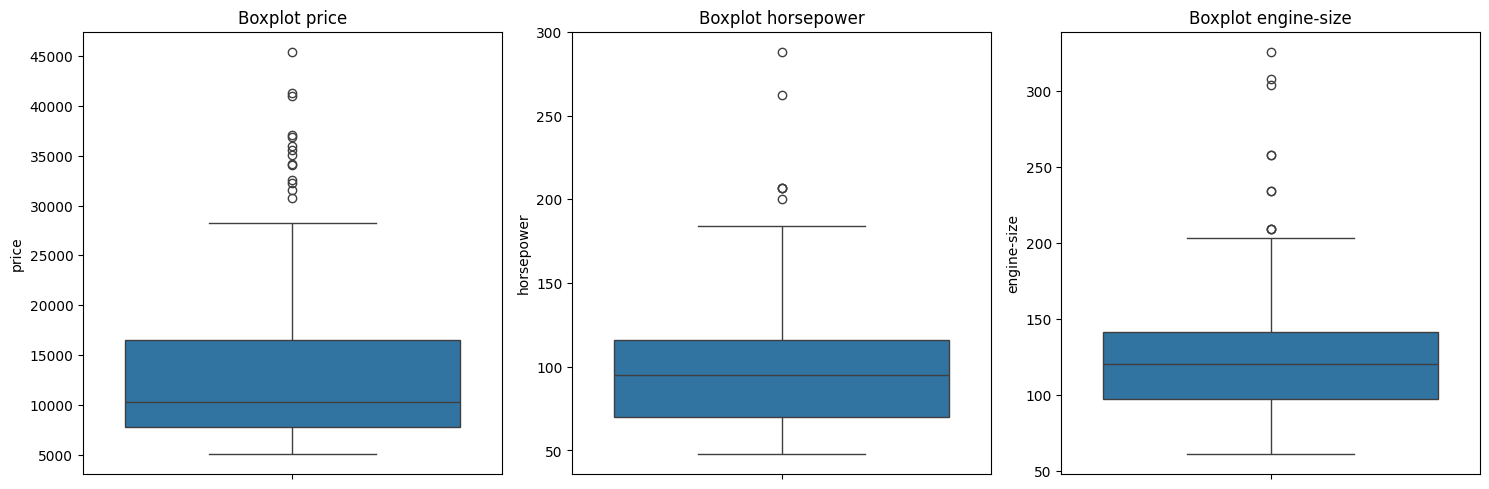

In [ ]:
# Pemeriksaan duplikasi
jml_duplikat = df.duplicated().sum()
print(f"\n--- Duplikasi Data ---")
print(f"Jumlah baris duplikat yang ditemukan: {jml_duplikat}")
if jml_duplikat > 0:
    print("Peringatan: Terdapat baris duplikat. Pastikan apakah ini merupakan perekaman ganda secara keliru sebelum menghapusnya.")

# Deteksi outlier dengan IQR untuk kolom numerik kontinu
print("\n--- Deteksi Outlier (Metode IQR) ---")
kolom_kontinu = ['price', 'horsepower', 'engine-size', 'normalized-losses', 'wheel-base', 'length', 'width', 'curb-weight', 'city-mpg', 'highway-mpg']

outlier_rekap = {}
for col in kolom_kontinu:
    if col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        batas_bawah = Q1 - 1.5 * IQR
        batas_atas = Q3 + 1.5 * IQR
        jumlah_outlier = ((df[col] < batas_bawah) | (df[col] > batas_atas)).sum()
        outlier_rekap[col] = jumlah_outlier

df_outlier = pd.DataFrame(list(outlier_rekap.items()), columns=['Kolom', 'Jumlah Outlier'])
display(df_outlier[df_outlier['Jumlah Outlier'] > 0])

# Visualisasi boxplot untuk beberapa kolom utama
kolom_plot = ['price', 'horsepower', 'engine-size']
plt.figure(figsize=(15, 5))
for i, col in enumerate(kolom_plot):
    if col in df.columns:
        plt.subplot(1, 3, i+1)
        sns.boxplot(y=df[col])
        plt.title(f'Boxplot {col}')
plt.tight_layout()
plt.show()

## Tahap 6: Pemeriksaan Hasil Akhir

Setelah melakukan berbagai tindakan pembersihan dan pengisian, mari kita bandingkan bentuk dan kondisi data sebelum dan sesudah diproses untuk memastikan semua berjalan sesuai rencana.

In [ ]:
print("--- PERBANDINGAN SEBELUM DAN SESUDAH PREPROCESSING ---\n")

print("1. Dimensi Data (Baris, Kolom):")
print(f"   Sebelum: {df_awal.shape}")
print(f"   Sesudah: {df.shape}")

print("\n2. Jumlah Total Missing Values (NaN atau '?'):")
awal_kosong = df_awal.isna().sum().sum() + (df_awal == '?').sum().sum()
akhir_kosong = df.isna().sum().sum()
print(f"   Sebelum: {awal_kosong}")
print(f"   Sesudah: {akhir_kosong}")

print("\n3. Jumlah Baris Duplikat:")
print(f"   Sebelum: {df_awal.duplicated().sum()}")
print(f"   Sesudah: {df.duplicated().sum()}")

print("\n--- Lima Baris Pertama Data Bersih ---")
display(df.head())

--- PERBANDINGAN SEBELUM DAN SESUDAH PREPROCESSING ---

1. Dimensi Data (Baris, Kolom):
   Sebelum: (205, 26)
   Sesudah: (205, 26)

2. Jumlah Total Missing Values (NaN atau '?'):
   Sebelum: 59
   Sesudah: 0

3. Jumlah Baris Duplikat:
   Sebelum: 0
   Sesudah: 0

--- Lima Baris Pertama Data Bersih ---


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,115.0,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,115.0,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,115.0,alfa-romero,gas,std,2.0,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,4.0,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,4.0,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


## Tahap 7: Penyimpanan

Tahap terakhir, kita menyimpan data yang sudah rapi ke dalam format Excel (.xlsx) beserta lembar audit imputasinya, dan juga format CSV untuk kepraktisan. Kita akan mengunduh langsung ke komputer Anda.

In [ ]:
# Instal pustaka xlsxwriter
!pip install xlsxwriter

# Simpan ke Excel dengan dua sheet
excel_filename = 'Automobile_Cleaned.xlsx'
with pd.ExcelWriter(excel_filename, engine='xlsxwriter') as writer:
    df.to_excel(writer, sheet_name='Data_Bersih', index=False)
    df_audit.to_excel(writer, sheet_name='Audit_Imputasi', index=False)

# Simpan juga ke format CSV
csv_filename = 'Automobile_Cleaned.csv'
df.to_csv(csv_filename, index=False)

print("Data berhasil disimpan sebagai file Excel dan CSV.")
print("Memulai proses pengunduhan otomatis...")

# Perintah untuk mengunduh ke perangkat pengguna
files.download(excel_filename)
files.download(csv_filename)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 4.9 MB/s eta 0:00:00
Data berhasil disimpan sebagai file Excel dan CSV.
Memulai proses pengunduhan otomatis...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>